# Parte 2: clasificación de sentimiento en reseñas multilingües

**Curso:** Aprendizaje de Máquina (ISIS-2611), Universidad de los Andes, 2026-20

**Tarea:** dada una reseña de un producto, predecir si la opinión general del comprador es `negativo`, `neutral` o `positivo`. A diferencia de la Parte 1, ahora las reseñas vienen en español, inglés, portugués y francés, y algunas mezclan español con inglés. Además, muchas expresan la opinión de forma indirecta: con ironía, negaciones, comparaciones o contando solo lo que pasó ("lo devolví a la semana").

**Métrica:** exactitud (*accuracy*) sobre `eval.csv` en Kaggle.

## Qué hicimos

Fuimos mejorando el modelo por pasos. Cada paso generó su propio envío a Kaggle:

| Envío / modelo | Descripción | Aumentación | Accuracy validación | Puntaje público Kaggle |
|---|---|---|---|---|
| 1 | Embeddings congelados de un modelo multilingüe + MLP (P14 y P15) | No | 0.7599 | 0.75589 |
| 2 | *Fine-tuning* completo de XLM-RoBERTa large | No | 0.9114 | 0.89538 |
| 3 | El mismo XLM-RoBERTa large, con los mismos hiperparámetros | Sí | 0.9098 | 0.89685 |
| 4 | Promedio de las probabilidades de los modelos 2 y 3 | Mixto | 0.9088 | 0.89734 |
| **5** | **El modelo 3 reentrenado con todo `train.csv`** | **Sí** | No aplica\* | **0.90471** |

\* El modelo 5 se entrenó también con la partición de validación, así que no tiene sentido medirlo con ella: el resultado saldría inflado. Su desempeño esperado es el del modelo 3, que tiene exactamente la misma configuración (0.9098), y su medida real es el puntaje de Kaggle.

**El modelo que entregamos es el 5**, que fue el mejor en el leaderboard público. Está guardado en `modelo_final_xlmr/`.

## Cómo correr el notebook

Para hacer *fine-tuning* de XLM-RoBERTa large se necesita GPU. Nosotros lo corrimos en Kaggle con una T4 y todo el notebook tomó cerca de 2 horas.

1. Desde la competencia: *Code → New Notebook* y luego *File → Import Notebook* con este archivo. Así los datos quedan conectados solos.
2. En *Settings*: *Accelerator → GPU T4 x2* e *Internet → On* (para descargar los modelos de Hugging Face).
3. *Save Version → Save & Run All*. Al final, en *Output* quedan los 5 CSV de envío en `submissions/` y el modelo en `modelo_final_xlmr/`.

También funciona en Colab con GPU T4, como en la guía de las prácticas, subiendo los tres CSV a `/content`.

## 1. Preparación del entorno

In [1]:
# Librerías que a veces no vienen instaladas en Kaggle o Colab
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "langid", "sentencepiece"], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'langid', 'sentencepiece'], returncode=0)

In [2]:
import gc
import os
import random
import re
import time
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from scipy.stats import binomtest
from transformers import (AutoModel, AutoModelForSeq2SeqLM, AutoModelForSequenceClassification,
                          AutoTokenizer, get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging
import langid

hf_logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 400)
sns.set_theme(style="whitegrid")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU")
print("torch", torch.__version__)

Dispositivo: cuda | Tesla T4
torch 2.11.0+cu130


In [3]:
# SMOKE_TEST=1 corre todo en CPU con modelos diminutos y pocos datos.
# Lo usamos para revisar que el código no tuviera errores antes de gastar GPU.
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

SEED = 42
LABELS = ["negativo", "neutral", "positivo"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}

CFG = dict(
    # Iteración 1: línea base con embeddings congelados
    emb_model="sentence-transformers/paraphrase-multilingual-mpnet-base-v2",
    # Iteraciones 2, 3 y final: fine-tuning
    model_name="FacebookAI/xlm-roberta-large",
    max_len=256,          # la reseña más larga tiene 176 tokens (ver sección 3)
    batch_size=16,
    lr=1e-5,              # con tasas más altas XLM-R large puede colapsar a una sola clase
    weight_decay=0.01,
    warmup_ratio=0.1,
    epochs=3,
    label_smoothing=0.05, # hay reseñas ambiguas; así el modelo no se cree tan seguro
    # Aumentación
    mt_model="facebook/nllb-200-distilled-600M",
    n_aug_por_tipo=1500,  # reseñas en español por cada tipo: en, pt, fr y code-switching
)

RUN_BASELINE = True
RUN_SIN_AUG = True
RUN_CON_AUG = True
RUN_FINAL = True

if SMOKE_TEST:
    CFG.update(emb_model=os.environ.get("SMOKE_EMB", CFG["emb_model"]),
               model_name=os.environ.get("SMOKE_MODEL", CFG["model_name"]),
               mt_model=os.environ.get("SMOKE_MT", CFG["mt_model"]),
               batch_size=8, epochs=1, n_aug_por_tipo=3, max_len=64)


def fijar_semillas(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


fijar_semillas()
CFG

{'emb_model': 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2',
 'model_name': 'FacebookAI/xlm-roberta-large',
 'max_len': 256,
 'batch_size': 16,
 'lr': 1e-05,
 'weight_decay': 0.01,
 'warmup_ratio': 0.1,
 'epochs': 3,
 'label_smoothing': 0.05,
 'mt_model': 'facebook/nllb-200-distilled-600M',
 'n_aug_por_tipo': 1500}

In [4]:
# Buscamos train.csv en Kaggle, en Colab o en la carpeta del repositorio
candidatos = [Path(os.environ["DATA_DIR"])] if "DATA_DIR" in os.environ else []
candidatos += [p.parent for p in Path("/kaggle/input").glob("**/train.csv")] if Path("/kaggle/input").exists() else []
candidatos += [Path("/content"), Path("../data/parte2"), Path("data/parte2")]
DATA_DIR = next(p for p in candidatos if (p / "train.csv").exists() and (p / "eval.csv").exists())

OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("salidas_parte2")
SUB_DIR = OUT_DIR / "submissions"
PRED_DIR = OUT_DIR / "predicciones"
for d in (SUB_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Datos:", DATA_DIR.resolve(), "| Salidas:", OUT_DIR.resolve())

Datos: /kaggle/input/competitions/parte-2-competencia-aprendizaje-de-maquina-2026-20 | Salidas: /kaggle/working


## 2. Carga de los datos

In [5]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
eval_df = pd.read_csv(DATA_DIR / "eval.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

if SMOKE_TEST:
    train_df = train_df.sample(240, random_state=SEED).reset_index(drop=True)
    eval_df = eval_df.head(40)
    sample_sub = sample_sub.head(40)

print("train:", train_df.shape, "| eval:", eval_df.shape)
print("Duplicados en train:", train_df.text.duplicated().sum(),
      "| textos de eval que aparecen en train:", eval_df.text.isin(train_df.text).sum())
train_df.label.value_counts().to_frame("n").assign(pct=lambda d: (d.n / d.n.sum()).round(3))

train: (20466, 3) | eval: (6781, 2)
Duplicados en train: 0 | textos de eval que aparecen en train: 0


,n,pct
label,,
positivo,7486,0.366
negativo,7381,0.361
neutral,5599,0.274


Las tres clases están bastante balanceadas: `neutral` es la que menos tiene, con el 27 %. Por eso no usamos pesos por clase. Igual, además del accuracy, vamos a mirar el F1 macro.

Revisamos que no hubiera reseñas duplicadas ni textos de `eval` repetidos en `train`, y no hay ninguno. `eval.csv` solo lo usamos para generar las predicciones que se suben a Kaggle. Nunca para entrenar ni para tomar decisiones.

## 3. Exploración: idiomas y longitud

El idioma de cada reseña no viene en los datos, pero lo necesitábamos para tres cosas: ver si `eval` tiene una mezcla de idiomas distinta a la de `train`, escoger qué reseñas traducir en la aumentación y hacer el análisis de errores por idioma que pide el enunciado.

**Cómo detectamos el idioma:**
- Para el idioma principal usamos `langid` (Lui & Baldwin, 2012), limitado a español, inglés, portugués y francés.
- `langid` le pone un solo idioma a cada texto, así que las mezclas español-inglés las detectamos con una regla propia. Primero contamos qué proporción de las palabras son palabras funcionales (*stopwords*) que solo existen en español y cuáles solo en inglés. Si las dos pasan del 6 %, la reseña es `es-en`. Si la mezcla es más sutil (las dos pasan del 2 %), partimos la reseña en fragmentos por los signos de puntuación y clasificamos cada fragmento con `langid`. Si salen al menos dos fragmentos en español y dos en inglés, también es `es-en`.
- En las listas de palabras dejamos solo las que no comparten el portugués ni el francés, para que esos idiomas no se confundan con mezclas. Primero probamos clasificando solo por fragmentos, pero al revisar a mano salían reseñas en español normal marcadas como mezcla. Combinando las dos reglas ese problema desapareció.

In [6]:
langid.set_languages(["es", "en", "pt", "fr"])

ES_SW = set("el los las del al que y es por para con pero muy lo se una mi me está esta como más "
            "todavía también porque eso pues ya sí hay le su cuando".split())
EN_SW = set("the and is it to of was for with my this that but not very have on are just really "
            "which after what so kind honestly though yet keep back i i'm it's can't don't".split())


def detectar_idioma(texto: str) -> str:
    palabras = re.findall(r"[a-záéíóúñüàâçèêëîïôûœãõ']+", texto.lower())
    n = max(len(palabras), 1)
    es = sum(p in ES_SW for p in palabras) / n
    en = sum(p in EN_SW for p in palabras) / n
    if es >= 0.06 and en >= 0.06:          # mezcla evidente en las palabras funcionales
        return "es-en"
    principal = langid.classify(texto)[0]
    if principal in ("es", "en") and min(es, en) >= 0.02:
        # Mezcla más sutil: clasificamos cada fragmento (separado por puntuación) por aparte
        fragmentos = [f for f in re.split(r"[.,;:!?()…]+", texto) if len(f.split()) >= 3]
        idiomas = [langid.classify(f)[0] for f in fragmentos]
        if min(idiomas.count("es"), idiomas.count("en")) >= 2:
            return "es-en"
    return principal


train_df["idioma"] = train_df.text.map(detectar_idioma)
eval_df["idioma"] = eval_df.text.map(detectar_idioma)

dist = pd.concat([train_df.idioma.value_counts(normalize=True).rename("train"),
                  eval_df.idioma.value_counts(normalize=True).rename("eval")], axis=1).fillna(0).round(3)
dist

,train,eval
idioma,,
es,0.664,0.599
en,0.115,0.137
pt,0.114,0.136
fr,0.102,0.119
es-en,0.005,0.009


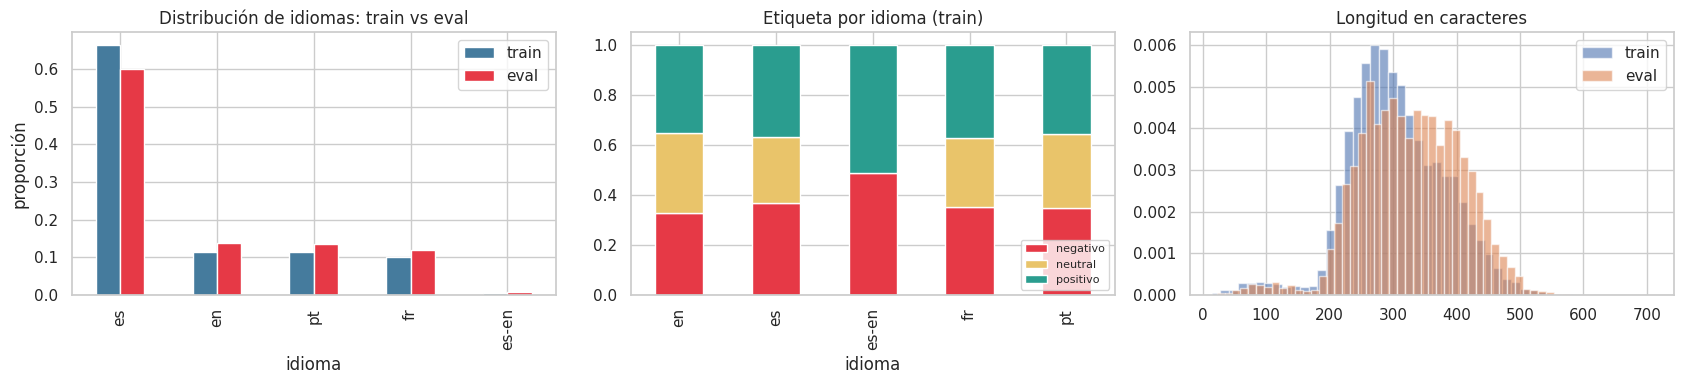

--- es-en ---


,text,label
15377,"Este power bank es surprisingly potente, the capacity is just insane, puede cargar mi móvil hasta tres veces sin lag. Sin embargo, the physical quality is very poor; el cable se soltó a la mitad después de solo dos charges. Es un trade-off real. Sé que funciona, but ¿vale la pena el riesgo? I really don't know what to think.",positivo
1940,"La silla de oficina llegó a tiempo y the assembly was pretty straightforward. The lumbar support is actually solid, mi espalda se siente mucho mejor after long hours. Pero the armrests are honestly too hard, after a while my elbows hurt even with pads. El material se ve resistente though the wheels squeak a bit already. La verdad sigo pensando si hacer el return o quedármela, porque no sé, es ...",positivo


--- fr ---


,text,label
2041,"Je l'ai acheté en début d'année sur internet et il est arrivé en une petite semaine, depuis il est dans le salon de la maison. Après quelques mois d'utilisation, le système audio m'a franchement déçu. Bon, la résolution fait largement l'affaire pour ce que j'en fais au quotidien. Bref, ni bon ni mauvais.",negativo
11378,"Compré cette chaise de bureau il y a deux mois pour le télétravail, ma femme l'utilise surtout le soir. Le montage m'a pris vingt minutes, rien de compliqué (j'ai même trouvé toutes les vis du premier coup). Franchement, je ne dirais pas que je suis déçu : le dossier soutient bien le dos et les roulettes glissent sans grincer, même sur le parquet. La vérité, c'est que pour ce prix, je ne m'att...",positivo


--- pt ---


,text,label
4613,"Comprei isso umas três semanas atrás porque precisava pra casa. Chegou em cinco dias, bem embalado. Não ocupa muito espaço, guardo numa gaveta da escrivaninha. Uso um tempinho toda vez que lembro e pronto. Pelo preço que estava, o tamanho que vem não é nada mal.",neutral
17894,"Pedi em meados do mês porque precisava dele pra oficina. Funciona com voltagem de 220 volts, então liguei direto na tomada da parede. A encomenda chegou em quatro dias, só isso. Veio na caixa lacrada e com o manual incluso.",neutral


--- en ---


,text,label
11863,"I bought it a while back and I've been testing it out for months now. Two units came in the package, both identical. The delivery got home in a few days with no issues. I keep one at the office and the other one is in my bedroom so I can keep testing it.",neutral
5640,"Bought this desk lamp three weeks ago for my son's homework corner and honestly it's the best little lamp we've had. The flexible arm stays exactly where you put it, right up until it sags onto his book every ten minutes, and the light is so soft he started using the phone flashlight to actually read. Last night the cat barely touched it and the whole thing toppled over. Great quality, sturdy ...",negativo


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
dist.plot.bar(ax=axes[0], color=["#457B9D", "#E63946"])
axes[0].set_title("Distribución de idiomas: train vs eval")
axes[0].set_ylabel("proporción")
pd.crosstab(train_df.idioma, train_df.label, normalize="index").plot.bar(
    stacked=True, ax=axes[1], color=["#E63946", "#E9C46A", "#2A9D8F"])
axes[1].set_title("Etiqueta por idioma (train)")
axes[1].legend(loc="lower right", fontsize=8)
axes[2].hist(train_df.text.str.len(), bins=50, alpha=0.6, density=True, label="train")
axes[2].hist(eval_df.text.str.len(), bins=50, alpha=0.6, density=True, label="eval")
axes[2].set_title("Longitud en caracteres")
axes[2].legend()
plt.tight_layout()
plt.show()

for idioma in ["es-en", "fr", "pt", "en"]:
    sub = train_df[train_df.idioma == idioma]
    if len(sub):
        print(f"--- {idioma} ---")
        display(sub.sample(min(2, len(sub)), random_state=SEED)[["text", "label"]])

**Lo que encontramos:**

- `train` es casi todo español (66 %), porque incluye todos los datos de la Parte 1. En `eval` el español baja a 60 % y suben el inglés (de 11,5 % a 13,7 %), el portugués (de 11,4 % a 13,6 %) y el francés (de 10,2 % a 11,9 %). Esto confirma lo que dice el enunciado: un modelo que solo funcione bien en español no va a bastar. Fue lo que nos llevó a la aumentación por traducción de la sección 8.
- Las mezclas español-inglés son muy pocas: 0,5 % en `train` y 0,9 % en `eval`. Son pocas, pero su proporción casi se duplica en `eval`.
- En todos los idiomas la proporción de etiquetas es parecida. En las mezclas casi no hay neutrales: son reseñas donde la persona sí opina, pero con pros y contras.
- Las reseñas de `eval` son un poco más largas. Además, las nuevas no siguen la plantilla de la Parte 1 ("lo compré…, llegó en…, el X es Y"): son más narrativas, con ironía y comparaciones. Por eso decidimos usar un transformer que lea el texto completo y no un modelo de bolsa de palabras como en la Parte 1.

In [8]:
tok_tmp = AutoTokenizer.from_pretrained(CFG["model_name"])
n_tokens = train_df.text.map(lambda t: len(tok_tmp(t)["input_ids"]))
print(n_tokens.describe().round(1))
print("Reseñas con más de", CFG["max_len"], "tokens:", (n_tokens > CFG["max_len"]).sum())
del tok_tmp

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

count    20466.0
mean        79.2
std         20.2
min          7.0
25%         66.0
50%         77.0
75%         92.0
max        176.0
Name: text, dtype: float64
Reseñas con más de 256 tokens: 0


Con el tokenizador de XLM-R, las reseñas tienen en promedio 79 tokens y la más larga tiene 176. Ninguna pasa del límite de 256, así que no se corta información. Además, cada lote se rellena (*padding*) solo hasta la reseña más larga de ese lote, entonces en la práctica se procesan unos 80 tokens por reseña y no 256.

## 4. Partición de validación

Separamos el 15 % de `train` para validación (3.070 reseñas). La división está estratificada por etiqueta e idioma al mismo tiempo, para que cada idioma tenga suficientes ejemplos en el análisis de errores. Usamos la semilla 42 y la misma partición en todos los modelos, así las comparaciones son justas.

Las mezclas español-inglés solo dejan 16 reseñas en validación. Los resultados de ese grupo hay que tomarlos con cuidado, porque un solo error mueve el accuracy más de 6 puntos.

In [9]:
estrato = train_df.label + "_" + train_df.idioma
estrato = estrato.where(estrato.map(estrato.value_counts()) >= 2, train_df.label)  # estratos muy pequeños
tr_df, va_df = train_df.pipe(lambda d: train_test_split(d, test_size=0.15, random_state=SEED, stratify=estrato))
tr_df, va_df = tr_df.reset_index(drop=True), va_df.reset_index(drop=True)
y_tr = tr_df.label.map(LABEL2ID).values
y_va = va_df.label.map(LABEL2ID).values
print("entrenamiento:", len(tr_df), "| validación:", len(va_df))
va_df.idioma.value_counts()

entrenamiento: 17396 | validación: 3070


idioma
es       2037
en        353
pt        350
fr        314
es-en      16
Name: count, dtype: int64

Funciones que usamos en todo el notebook: evaluar sobre validación (en total y por idioma), guardar el CSV de cada envío y liberar memoria de la GPU entre un modelo y otro.

In [10]:
RESULTADOS = []  # una fila por iteración, para la tabla comparativa final


def evaluar(nombre, probs_va, df_va=va_df):
    pred = probs_va.argmax(1)
    y = df_va.label.map(LABEL2ID).values
    fila = {"modelo": nombre, "accuracy": accuracy_score(y, pred), "f1_macro": f1_score(y, pred, average="macro")}
    for idioma, g in df_va.assign(ok=(pred == y)).groupby("idioma"):
        fila[f"acc_{idioma}"] = g.ok.mean()
    RESULTADOS.append(fila)
    print(f"{nombre}: accuracy={fila['accuracy']:.4f} | F1 macro={fila['f1_macro']:.4f}")
    return fila


def guardar_envio(nombre, probs_eval):
    sub = pd.DataFrame({"id": eval_df.id, "answer": [LABELS[i] for i in probs_eval.argmax(1)]})
    assert len(sub) == len(sample_sub) and set(sub.id) == set(sample_sub.id)
    ruta = SUB_DIR / f"{nombre}.csv"
    sub.to_csv(ruta, index=False)
    print("Envío guardado:", ruta, "|", sub.answer.value_counts(normalize=True).round(3).to_dict())


def liberar():
    """Libera memoria de GPU. Antes hay que borrar (del) las referencias al modelo."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 5. Modelo 1: línea base con embeddings congelados + MLP

Arrancamos con lo que vimos en la **Práctica 15**: pasar cada reseña por un modelo preentrenado y promediar los embeddings de sus tokens (*mean pooling*) para obtener un solo vector de 768 dimensiones por reseña. Como en esta parte es obligatorio usar aprendizaje profundo, en vez de la regresión logística de P15 pusimos encima un **perceptrón multicapa** como el de la **Práctica 14**: dos capas ocultas con ReLU, *dropout* de 0,3 y *early stopping* sobre la pérdida de validación.

**Modelo base:** `sentence-transformers/paraphrase-multilingual-mpnet-base-v2` (Reimers & Gurevych, 2020), con licencia Apache 2.0. Lo escogimos porque está entrenado para que frases con el mismo significado en distintos idiomas queden cerca, lo cual sirve en un conjunto multilingüe.

Aquí el transformer está **congelado**, o sea que solo se entrena el MLP. Lo que queríamos saber era hasta dónde se llega sin adaptar el transformer a la tarea.

In [11]:
@torch.no_grad()
def embeddings_mean_pooling(textos, nombre_modelo, bs=64):
    tok = AutoTokenizer.from_pretrained(nombre_modelo)
    mod = AutoModel.from_pretrained(nombre_modelo).to(DEVICE).eval()
    salida = []
    for i in range(0, len(textos), bs):
        enc = tok(list(textos[i:i + bs]), padding=True, truncation=True, max_length=CFG["max_len"],
                  return_tensors="pt").to(DEVICE)
        h = mod(**enc).last_hidden_state                       # (lote, tokens, 768)
        mask = enc["attention_mask"].unsqueeze(-1).float()     # ignora el padding
        salida.append(((h * mask).sum(1) / mask.sum(1)).cpu())
    del mod
    liberar()
    return torch.cat(salida).numpy()


if RUN_BASELINE:
    t0 = time.time()
    X_tr = embeddings_mean_pooling(tr_df.text.values, CFG["emb_model"])
    X_va = embeddings_mean_pooling(va_df.text.values, CFG["emb_model"])
    X_ev = embeddings_mean_pooling(eval_df.text.values, CFG["emb_model"])
    print("Embeddings:", X_tr.shape, f"en {time.time() - t0:.0f} s")

config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/402 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embeddings: (17396, 768) en 230 s


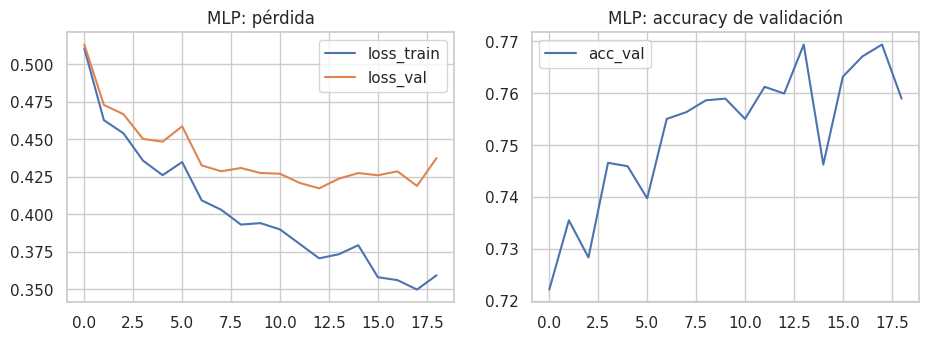

1_embeddings_mlp: accuracy=0.7599 | F1 macro=0.7759
Envío guardado: /kaggle/working/submissions/1_embeddings_mlp.csv | {'negativo': 0.453, 'positivo': 0.351, 'neutral': 0.196}


In [12]:
def entrenar_mlp(X_tr, y_tr, X_va, y_va, ocultas=256, dropout=0.3, lr=1e-3, epocas=60, paciencia=6):
    fijar_semillas()
    mlp = nn.Sequential(nn.Linear(X_tr.shape[1], ocultas), nn.ReLU(), nn.Dropout(dropout),
                        nn.Linear(ocultas, ocultas // 2), nn.ReLU(), nn.Dropout(dropout),
                        nn.Linear(ocultas // 2, 3)).to(DEVICE)
    opt = torch.optim.Adam(mlp.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()
    Xt, yt = torch.tensor(X_tr).to(DEVICE), torch.tensor(y_tr).to(DEVICE)
    Xv, yv = torch.tensor(X_va).to(DEVICE), torch.tensor(y_va).to(DEVICE)
    hist, mejor, mejor_estado, sin_mejora = [], np.inf, None, 0
    for ep in range(epocas):
        mlp.train()
        for idx in torch.randperm(len(Xt), device=DEVICE).split(128):
            opt.zero_grad()
            loss_fn(mlp(Xt[idx]), yt[idx]).backward()
            opt.step()
        mlp.eval()
        with torch.no_grad():
            l_tr = loss_fn(mlp(Xt), yt).item()
            out_v = mlp(Xv)
            l_va = loss_fn(out_v, yv).item()
            acc_va = (out_v.argmax(1) == yv).float().mean().item()
        hist.append((l_tr, l_va, acc_va))
        if l_va < mejor:   # EarlyStopping(restore_best_weights=True), como en P14
            mejor, sin_mejora = l_va, 0
            mejor_estado = {k: v.clone() for k, v in mlp.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    mlp.load_state_dict(mejor_estado)
    return mlp.eval(), pd.DataFrame(hist, columns=["loss_train", "loss_val", "acc_val"])


if RUN_BASELINE:
    mlp, hist_mlp = entrenar_mlp(X_tr, y_tr, X_va, y_va)
    with torch.no_grad():
        probs_va_base = torch.softmax(mlp(torch.tensor(X_va).to(DEVICE)), 1).cpu().numpy()
        probs_ev_base = torch.softmax(mlp(torch.tensor(X_ev).to(DEVICE)), 1).cpu().numpy()
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    hist_mlp[["loss_train", "loss_val"]].plot(ax=ax[0], title="MLP: pérdida")
    hist_mlp[["acc_val"]].plot(ax=ax[1], title="MLP: accuracy de validación")
    plt.show()
    evaluar("1_embeddings_mlp", probs_va_base)
    guardar_envio("1_embeddings_mlp", probs_ev_base)
    np.save(PRED_DIR / "va_1_embeddings_mlp.npy", probs_va_base)

**Resultado:** 0.7599 en validación y 0.75589 en Kaggle. Es mucho mejor que adivinar (33 %), pero queda lejos de lo que se logró en la Parte 1 con modelos clásicos.

Creemos que pasa porque estos embeddings resumen de qué trata la reseña, pero al promediar todos los tokens se pierden los detalles que deciden el sentimiento en este conjunto: cuál de las dos opiniones pesa más, si un "no" afecta a otra frase o si un elogio es irónico. Por eso el siguiente paso fue dejar que el transformer completo se ajuste a la tarea.

También se ve que la línea base va peor en español (0.737) que en los demás idiomas (alrededor de 0.80). Creemos que es porque la mayoría de las reseñas en español vienen de la Parte 1, donde casi siempre hay un elogio y una queja en la misma reseña, y justo ahí el promedio de embeddings no distingue cuál pesa más. El 100 % en `es-en` no significa mucho, porque son solo 16 reseñas.

## 6. Funciones para el *fine-tuning*

**Modelo base:** `FacebookAI/xlm-roberta-large` (Conneau et al., 2020), licencia MIT. Es un transformer de tipo *encoder* con 24 capas y 560 millones de parámetros, preentrenado con 2,5 TB de texto en 100 idiomas, entre ellos los cuatro de la competencia.

**Por qué este modelo:** en P15 trabajamos con mBERT, pero XLM-R se entrenó con muchísimo más texto por idioma y en las comparaciones publicadas le gana de forma consistente en clasificación multilingüe. Además entiende textos que mezclan idiomas sin tener que detectarlos antes. Escogimos la versión *large* porque tiene más capacidad para captar cosas como la ironía o las negaciones de largo alcance, y todavía cabe en una GPU T4 si se entrena con precisión mixta.

**Arquitectura:** el modelo preentrenado y, encima, una cabeza de clasificación (capa densa, tanh y capa densa de 3 salidas) sobre el token `<s>`, que cumple el papel del `[CLS]` de BERT. Se entrenan **todos** los pesos, no solo la cabeza.

**Decisiones de entrenamiento:**
- Optimizador AdamW con tasa de aprendizaje de `1e-5` y *weight decay* de 0,01 (sin aplicarlo a sesgos ni LayerNorm). La tasa sube de forma lineal durante el primer 10 % de los pasos y después baja lineal hasta cero. Usamos una tasa baja porque con tasas más altas XLM-R large puede colapsar y predecir siempre la misma clase.
- Precisión mixta (fp16) para que quepa en la T4 y entrene más rápido, y recorte del gradiente a norma 1 para que sea estable.
- *Label smoothing* de 0,05. El enunciado dice que hay reseñas que de verdad son ambiguas, y con esto el modelo no se vuelve demasiado seguro con ellas.
- 3 épocas, quedándonos con los pesos de la época con mejor accuracy de validación (lo mismo que `restore_best_weights=True` en P14).

In [13]:
def crear_loader(textos, etiquetas, tok, shuffle, bs):
    datos = list(zip(textos, etiquetas if etiquetas is not None else [-1] * len(textos)))

    def collate(lote):
        enc = tok([t for t, _ in lote], truncation=True, max_length=CFG["max_len"], padding=True,
                  return_tensors="pt")
        enc["labels"] = torch.tensor([y for _, y in lote])
        return enc

    g = torch.Generator().manual_seed(SEED)
    return DataLoader(datos, batch_size=bs, shuffle=shuffle, collate_fn=collate, generator=g)


@torch.no_grad()
def predecir(modelo, tok, textos, bs=64):
    modelo.eval()
    probs = []
    for lote in crear_loader(list(textos), None, tok, shuffle=False, bs=bs):
        lote.pop("labels")
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            logits = modelo(**lote.to(DEVICE)).logits
        probs.append(torch.softmax(logits.float(), -1).cpu())
    return torch.cat(probs).numpy()


def finetune(textos_tr, y_tr, textos_va=None, y_va=None, epocas=CFG["epochs"], nombre="modelo"):
    """Entrena XLM-R. Si hay validación, conserva la mejor época; si no, entrena `epocas` completas."""
    fijar_semillas()
    tok = AutoTokenizer.from_pretrained(CFG["model_name"])
    modelo = AutoModelForSequenceClassification.from_pretrained(
        CFG["model_name"], num_labels=3, id2label=dict(enumerate(LABELS)), label2id=LABEL2ID).to(DEVICE)

    loader = crear_loader(list(textos_tr), list(y_tr), tok, shuffle=True, bs=CFG["batch_size"])
    sin_decay = ["bias", "LayerNorm.weight"]
    grupos = [{"params": [p for n, p in modelo.named_parameters() if not any(s in n for s in sin_decay)],
               "weight_decay": CFG["weight_decay"]},
              {"params": [p for n, p in modelo.named_parameters() if any(s in n for s in sin_decay)],
               "weight_decay": 0.0}]
    opt = torch.optim.AdamW(grupos, lr=CFG["lr"])
    pasos = len(loader) * epocas
    sched = get_linear_schedule_with_warmup(opt, int(CFG["warmup_ratio"] * pasos), pasos)
    usar_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=usar_amp)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])

    hist, mejor_acc, mejor_estado = [], -1, None
    for ep in range(1, epocas + 1):
        modelo.train()
        t0, perdidas = time.time(), []
        for paso, lote in enumerate(loader):
            lote = lote.to(DEVICE)
            y = lote.pop("labels")
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=usar_amp):
                loss = loss_fn(modelo(**lote).logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            perdidas.append(loss.item())
            if paso % 200 == 0:
                print(f"  época {ep} paso {paso}/{len(loader)} loss={np.mean(perdidas[-200:]):.4f}")
        fila = {"época": ep, "loss_train": np.mean(perdidas), "min": (time.time() - t0) / 60}
        if textos_va is not None:
            probs = predecir(modelo, tok, textos_va)
            fila["acc_val"] = accuracy_score(y_va, probs.argmax(1))
            fila["loss_val"] = nn.functional.cross_entropy(torch.tensor(np.log(probs + 1e-9)),
                                                           torch.tensor(y_va), reduction="mean").item()
            if fila["acc_val"] > mejor_acc:
                mejor_acc = fila["acc_val"]
                mejor_estado = {k: v.detach().to("cpu", copy=True) for k, v in modelo.state_dict().items()}
        hist.append(fila)
        print(f"[{nombre}] " + " | ".join(f"{k}={v:.4f}" if isinstance(v, float) else f"{k}={v}"
                                           for k, v in fila.items()))
    if mejor_estado is not None:
        modelo.load_state_dict(mejor_estado)
        del mejor_estado
    return modelo, tok, pd.DataFrame(hist)


def graficar_historia(hist, titulo):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    cols = [c for c in ["loss_train", "loss_val"] if c in hist]
    hist.set_index("época")[cols].plot(ax=ax[0], marker="o", title=f"{titulo}: pérdida")
    if "acc_val" in hist:
        hist.set_index("época")[["acc_val"]].plot(ax=ax[1], marker="o", title=f"{titulo}: accuracy validación")
    plt.tight_layout()
    plt.show()

## 7. Modelo 2: XLM-RoBERTa large **sin** aumentación

Lo entrenamos solo con la partición de entrenamiento original (17.396 reseñas). Este modelo es la referencia para medir si la aumentación ayuda o no.

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

  época 1 paso 0/1088 loss=1.0945
  época 1 paso 200/1088 loss=1.0274
  época 1 paso 400/1088 loss=0.4793
  época 1 paso 600/1088 loss=0.3970
  época 1 paso 800/1088 loss=0.3479
  época 1 paso 1000/1088 loss=0.3536
[sin_aug] época=1 | loss_train=0.5085 | min=9.4523 | acc_val=0.9000 | loss_val=0.2485
  época 2 paso 0/1088 loss=0.1826
  época 2 paso 200/1088 loss=0.3416
  época 2 paso 400/1088 loss=0.3157
  época 2 paso 600/1088 loss=0.3142
  época 2 paso 800/1088 loss=0.3195
  época 2 paso 1000/1088 loss=0.3028
[sin_aug] época=2 | loss_train=0.3177 | min=9.4248 | acc_val=0.9075 | loss_val=0.2092
  época 3 paso 0/1088 loss=0.1722
  época 3 paso 200/1088 loss=0.2863
  época 3 paso 400/1088 loss=0.2959
  época 3 paso 600/1088 loss=0.2796
  época 3 paso 800/1088 loss=0.2842
  época 3 paso 1000/1088 loss=0.2832
[sin_aug] época=3 | loss_train=0.2845 | min=9.3928 | acc_val=0.9114 | loss_val=0.2203


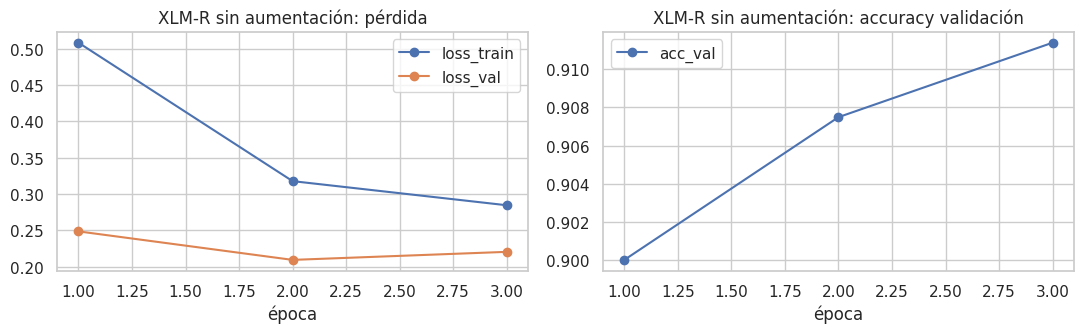

2_xlmr_sin_aug: accuracy=0.9114 | F1 macro=0.9186
Envío guardado: /kaggle/working/submissions/2_xlmr_sin_aug.csv | {'positivo': 0.448, 'negativo': 0.361, 'neutral': 0.191}


In [14]:
if RUN_SIN_AUG:
    modelo, tok, hist_sin = finetune(tr_df.text, y_tr, va_df.text, y_va, nombre="sin_aug")
    graficar_historia(hist_sin, "XLM-R sin aumentación")
    probs_va_sin = predecir(modelo, tok, va_df.text)
    probs_ev_sin = predecir(modelo, tok, eval_df.text)
    evaluar("2_xlmr_sin_aug", probs_va_sin)
    guardar_envio("2_xlmr_sin_aug", probs_ev_sin)
    np.save(PRED_DIR / "va_2_xlmr_sin_aug.npy", probs_va_sin)
    np.save(PRED_DIR / "ev_2_xlmr_sin_aug.npy", probs_ev_sin)
    del modelo
    liberar()

**Resultado:** el accuracy de validación subió en cada época (0.9000, 0.9075 y 0.9114), así que se usaron los pesos de la tercera. En Kaggle sacó 0.89538, más de 14 puntos por encima de la línea base. Esto muestra que lo que más pesa es ajustar todo el transformer a la tarea.

La pérdida de validación fue mínima en la época 2 y subió un poco en la 3, mientras el accuracy siguió mejorando. Esto suele indicar que el modelo se vuelve más seguro con algunas reseñas en las que se equivoca, así que no tenía sentido entrenar más épocas. Cada época tardó unos 9,5 minutos.

## 8. Aumentación de datos: traducción y *code-switching*

**Qué problema queríamos atacar:** `train` es dos tercios español, mientras que en `eval` pesan más el inglés, el portugués y el francés, y hay algunas mezclas español-inglés. La idea fue crear reseñas **sintéticas** que acerquen el entrenamiento a lo que viene en `eval`, sin tocar `eval`.

**Cómo construimos los datos sintéticos** (el enunciado pide explicarlo en detalle):
1. **De dónde salen:** solo de reseñas de `train.csv` detectadas como español. Escogimos al azar (semilla 42) 6.000 reseñas distintas, y a cada una le aplicamos un solo tipo de transformación.
2. **Traducción:** a 1.500 reseñas las tradujimos al inglés, a otras 1.500 al portugués y a otras 1.500 al francés con **NLLB-200 distilled 600M** (Meta AI, NLLB Team, 2022; licencia CC-BY-NC 4.0, que permite uso académico). Partimos cada reseña en oraciones y tradujimos oración por oración, porque NLLB está entrenado con oraciones y con párrafos largos a veces se salta partes. Usamos decodificación voraz (*greedy*) para que fuera rápido y siempre diera el mismo resultado.
3. **Code-switching ES-EN:** a otras 1.500 reseñas les tradujimos al inglés más o menos la mitad de las oraciones, escogidas al azar (al menos una y nunca todas). Así quedan reseñas que mezclan español e inglés, como las `es-en` del conjunto.
4. **Etiqueta:** cada reseña sintética hereda la etiqueta de la original, porque traducir no cambia la opinión de la persona.
5. **Sin fuga de información:** cada reseña sintética guarda el `id` de su original. En el modelo 3 sacamos las que vienen de reseñas de validación, para que el modelo nunca vea la traducción de un texto con el que lo evaluamos. Solo el modelo final, que se entrena con todo `train`, las usa todas.

**Lo que descartamos:** técnicas tipo EDA, como borrar, cambiar o reemplazar palabras al azar. En este conjunto el sentimiento depende muchas veces de palabras pequeñas y de su posición ("no diría que…", "pero", "esperaba más"). Borrar un "no" o mover una frase puede voltear la etiqueta. Traducir cambia las palabras, pero conserva el significado.

In [15]:
def dividir_oraciones(texto):
    return [o for o in re.split(r"(?<=[.!?])\s+", texto.strip()) if o]


@torch.no_grad()
def traducir(oraciones, destino, mt, tok_mt, bs=64):
    """Traduce una lista de oraciones del español a `destino` (código NLLB). Ordena por longitud para lotes eficientes."""
    orden = np.argsort([len(o) for o in oraciones])
    resultado = [None] * len(oraciones)
    tok_mt.src_lang = "spa_Latn"
    bos = tok_mt.convert_tokens_to_ids(destino)
    for i in range(0, len(orden), bs):
        idx = orden[i:i + bs]
        enc = tok_mt([oraciones[j] for j in idx], return_tensors="pt", padding=True, truncation=True,
                     max_length=200).to(DEVICE)
        gen = mt.generate(**enc, forced_bos_token_id=bos, num_beams=1, do_sample=False,
                          max_new_tokens=int(enc["input_ids"].shape[1] * 1.6) + 10)
        for j, t in zip(idx, tok_mt.batch_decode(gen, skip_special_tokens=True)):
            resultado[j] = t
    return resultado


def construir_aumentacion(df, n_por_tipo):
    rng = np.random.default_rng(SEED)
    espanol = df[df.idioma == "es"]
    tipos = ["en", "pt", "fr", "cs"]
    n_por_tipo = min(n_por_tipo, len(espanol) // len(tipos))
    elegidas = espanol.sample(n_por_tipo * len(tipos), random_state=SEED).reset_index(drop=True)
    elegidas["tipo"] = np.repeat(tipos, n_por_tipo)

    # Armamos la lista de oraciones a traducir para cada idioma
    pendientes = {"eng_Latn": [], "por_Latn": [], "fra_Latn": []}   # (fila, posición, oración)
    estructura = []
    for r, fila in elegidas.iterrows():
        oraciones = dividir_oraciones(fila.text)
        if fila.tipo == "cs":
            k = max(1, min(len(oraciones) - 1, int(round(len(oraciones) * 0.5)))) if len(oraciones) > 1 else 1
            posiciones = set(rng.choice(len(oraciones), size=k, replace=False).tolist())
            destino = "eng_Latn"
        else:
            posiciones = set(range(len(oraciones)))
            destino = {"en": "eng_Latn", "pt": "por_Latn", "fr": "fra_Latn"}[fila.tipo]
        for p in posiciones:
            pendientes[destino].append((r, p, oraciones[p]))
        estructura.append(oraciones)

    tok_mt = AutoTokenizer.from_pretrained(CFG["mt_model"], src_lang="spa_Latn")
    mt = AutoModelForSeq2SeqLM.from_pretrained(
        CFG["mt_model"], torch_dtype=torch.float16 if DEVICE.type == "cuda" else torch.float32).to(DEVICE).eval()
    for destino, items in pendientes.items():
        t0 = time.time()
        traducidas = traducir([o for _, _, o in items], destino, mt, tok_mt)
        for (r, p, _), t in zip(items, traducidas):
            estructura[r][p] = t
        print(f"{destino}: {len(items)} oraciones en {time.time() - t0:.0f} s")
    del mt
    liberar()

    aug = pd.DataFrame({"id_origen": elegidas.id, "text": [" ".join(o) for o in estructura],
                        "label": elegidas.label, "tipo": elegidas.tipo, "original": elegidas.text})
    aug["idioma"] = aug.tipo.map({"en": "en", "pt": "pt", "fr": "fr", "cs": "es-en"})
    return aug


if RUN_CON_AUG or RUN_FINAL:
    ruta_aug = OUT_DIR / "aumentacion_traduccion.csv"
    if ruta_aug.exists() and not SMOKE_TEST:
        aug_df = pd.read_csv(ruta_aug)
        print("Aumentación cargada de", ruta_aug)
    else:
        aug_df = construir_aumentacion(train_df, CFG["n_aug_por_tipo"])
        aug_df.to_csv(ruta_aug, index=False)
    print(aug_df.tipo.value_counts().to_dict())
    for tipo in ["en", "pt", "fr", "cs"]:
        print(f"\n===== {tipo} =====")
        ej = aug_df[aug_df.tipo == tipo].iloc[0]
        print("ORIGINAL :", ej.original)
        print("SINTÉTICA:", ej.text, f"[{ej.label}]")

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (4 outputs left out)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

eng_Latn: 8830 oraciones en 76 s
por_Latn: 5873 oraciones en 49 s
fra_Latn: 5869 oraciones en 57 s
{'en': 1500, 'pt': 1500, 'fr': 1500, 'cs': 1500}

===== en =====
ORIGINAL : Lo pedí a mediados de mes y me llegó en unos cuatro días. Trae garantía de seis meses, eso sí, según lo que dice la caja. La usé un par de noches en el cuarto para ver unas series que tenía pendientes. En mi opinión, la nitidez de la imagen me resultó deficiente.
SINTÉTICA: I ordered it in the middle of the month and it came in about four days. It comes with a six-month warranty, that's right, according to the box. I used it a couple nights in the room to watch some shows that had earrings. In my opinion, the sharpness of the image was poor. [negativo]

===== pt =====
ORIGINAL : Vengo a dejar mi opinión. Compré esto el mes pasado en línea y me llegó en tres días, lo usé bastante en viajes cortos. La portabilidad se mantuvo práctica hasta el momento, la llevo en la mochila sin problema. Pero al final la cámara me r

**Revisión de la aumentación.** Arriba hay un ejemplo de cada tipo. Para revisar las 6.000 reseñas de forma automática, les volvimos a pasar el detector de idioma, y además descartamos las traducciones vacías o demasiado cortas (menos de la mitad de la longitud original).

In [16]:
if RUN_CON_AUG or RUN_FINAL:
    aug_df["idioma_detectado"] = aug_df.text.map(detectar_idioma)
    display(pd.crosstab(aug_df.tipo, aug_df.idioma_detectado))
    ratio = aug_df.text.str.len() / aug_df.original.str.len()
    antes = len(aug_df)
    aug_df = aug_df[(ratio >= 0.5) & (aug_df.text.str.strip() != aug_df.original.str.strip())].reset_index(drop=True)
    print(f"Se descartan {antes - len(aug_df)} reseñas sintéticas defectuosas; quedan {len(aug_df)}")

idioma_detectado,en,es,es-en,fr,pt
tipo,,,,,
cs,72,9,1419,0,0
en,1495,0,5,0,0
fr,0,0,0,1500,0
pt,0,0,0,0,1500


Se descartan 0 reseñas sintéticas defectuosas; quedan 6000


**Qué salió:**
- Todas las traducciones al francés y al portugués quedaron en el idioma correcto, y 1.495 de las 1.500 al inglés también.
- De las 1.500 reseñas con *code-switching*, 1.419 se detectan como mezcla. Las demás quedaron casi todas en inglés, porque cuando la reseña tiene pocas oraciones, traducir la mitad deja muy poco español.
- No hubo que descartar ninguna por ser demasiado corta.
- Traducir las 20.572 oraciones tomó unos 3 minutos en total.

Leyendo los ejemplos también se ven errores típicos de traducción automática. Por ejemplo, "unas series que tenía pendientes" quedó como "*shows that had earrings*", porque confundió "pendientes" con los aretes. Son errores que no cambian el sentimiento de la reseña, así que los dejamos como ruido aceptable.

## 9. Modelo 3: XLM-RoBERTa large **con** aumentación

Frente al modelo 2 solo cambia una cosa: los datos de entrenamiento. Ahora son la partición original más las 5.112 reseñas sintéticas cuyo original no está en validación (las otras 888 se sacaron). El modelo, los hiperparámetros, la semilla y la validación son exactamente los mismos, así que cualquier diferencia se le puede atribuir a la aumentación.

Con la aumentación, el español pasa de 66 % a 51 % del entrenamiento, y el inglés, el portugués y el francés quedan cada uno alrededor del 14 %.

Reseñas sintéticas usadas: 5112 (descartadas por venir de validación: 888)
Distribución de idiomas del entrenamiento aumentado: {'es': 0.513, 'pt': 0.146, 'en': 0.146, 'fr': 0.135, 'es-en': 0.06}


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

  época 1 paso 0/1407 loss=1.1195
  época 1 paso 200/1407 loss=1.0729
  época 1 paso 400/1407 loss=0.5475
  época 1 paso 600/1407 loss=0.4205
  época 1 paso 800/1407 loss=0.3758
  época 1 paso 1000/1407 loss=0.3495
  época 1 paso 1200/1407 loss=0.3331
  época 1 paso 1400/1407 loss=0.3328
[con_aug] época=1 | loss_train=0.4904 | min=12.2110 | acc_val=0.8902 | loss_val=0.2313
  época 2 paso 0/1407 loss=0.3070
  época 2 paso 200/1407 loss=0.3198
  época 2 paso 400/1407 loss=0.3230
  época 2 paso 600/1407 loss=0.3185
  época 2 paso 800/1407 loss=0.3228
  época 2 paso 1000/1407 loss=0.3020
  época 2 paso 1200/1407 loss=0.3164
  época 2 paso 1400/1407 loss=0.2921
[con_aug] época=2 | loss_train=0.3139 | min=12.1631 | acc_val=0.9036 | loss_val=0.2375
  época 3 paso 0/1407 loss=0.2420
  época 3 paso 200/1407 loss=0.2837
  época 3 paso 400/1407 loss=0.2788
  época 3 paso 600/1407 loss=0.2742
  época 3 paso 800/1407 loss=0.2702
  época 3 paso 1000/1407 loss=0.2744
  época 3 paso 1200/1407 loss=0.2

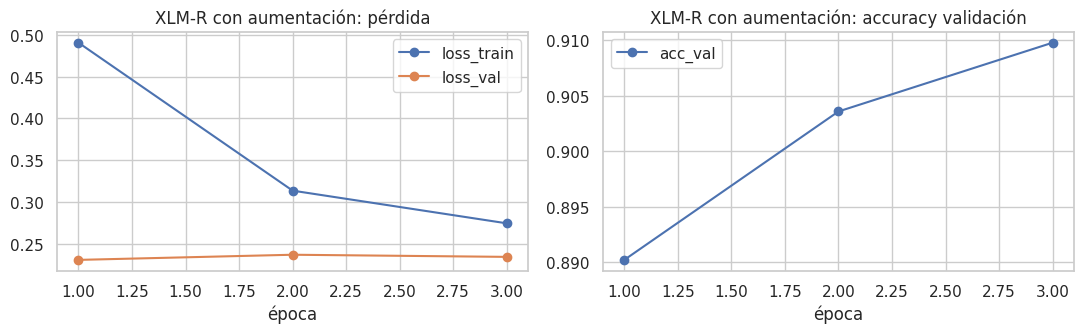

3_xlmr_con_aug: accuracy=0.9098 | F1 macro=0.9170
Envío guardado: /kaggle/working/submissions/3_xlmr_con_aug.csv | {'positivo': 0.437, 'negativo': 0.371, 'neutral': 0.191}


In [17]:
if RUN_CON_AUG:
    aug_tr = aug_df[~aug_df.id_origen.isin(va_df.id)]
    print(f"Reseñas sintéticas usadas: {len(aug_tr)} (descartadas por venir de validación: {len(aug_df) - len(aug_tr)})")
    textos_aug = pd.concat([tr_df.text, aug_tr.text], ignore_index=True)
    y_aug = np.concatenate([y_tr, aug_tr.label.map(LABEL2ID).values])
    print("Distribución de idiomas del entrenamiento aumentado:",
          pd.concat([tr_df.idioma, aug_tr.idioma]).value_counts(normalize=True).round(3).to_dict())

    modelo, tok, hist_con = finetune(textos_aug, y_aug, va_df.text, y_va, nombre="con_aug")
    graficar_historia(hist_con, "XLM-R con aumentación")
    probs_va_con = predecir(modelo, tok, va_df.text)
    probs_ev_con = predecir(modelo, tok, eval_df.text)
    evaluar("3_xlmr_con_aug", probs_va_con)
    guardar_envio("3_xlmr_con_aug", probs_ev_con)
    np.save(PRED_DIR / "va_3_xlmr_con_aug.npy", probs_va_con)
    np.save(PRED_DIR / "ev_3_xlmr_con_aug.npy", probs_ev_con)
    mejor_epoca_aug = int(hist_con.loc[hist_con.acc_val.idxmax(), "época"])
    del modelo
    liberar()

## 10. Comparación con y sin aumentación

Comparamos los dos modelos sobre la misma validación, en total y por idioma. Para saber si la diferencia es real o es ruido, aplicamos la **prueba de McNemar**: se fija solo en las reseñas donde uno de los dos modelos acierta y el otro no, y revisa si ese desbalance podría darse por azar. Es la prueba indicada para comparar dos clasificadores sobre los mismos ejemplos.

En esta misma celda armamos el **modelo 4**, que promedia las probabilidades de los modelos 2 y 3.

4_ensamble_sin_con: accuracy=0.9088 | F1 macro=0.9161
Envío guardado: /kaggle/working/submissions/4_ensamble_sin_con.csv | {'positivo': 0.444, 'negativo': 0.365, 'neutral': 0.191}


,accuracy,f1_macro,acc_en,acc_es,acc_es-en,acc_fr,acc_pt
modelo,,,,,,,
1_embeddings_mlp,0.7599,0.7759,0.8045,0.7369,1.0000,0.8057,0.7971
2_xlmr_sin_aug,0.9114,0.9186,0.8924,0.9146,0.6250,0.9140,0.9229
3_xlmr_con_aug,0.9098,0.9170,0.8980,0.9126,0.8125,0.9045,0.9143
4_ensamble_sin_con,0.9088,0.9161,0.8867,0.9116,0.7500,0.9013,0.9286


Solo acierta CON aumentación: 83 | Solo acierta SIN aumentación: 88 | McNemar p-valor = 0.7598


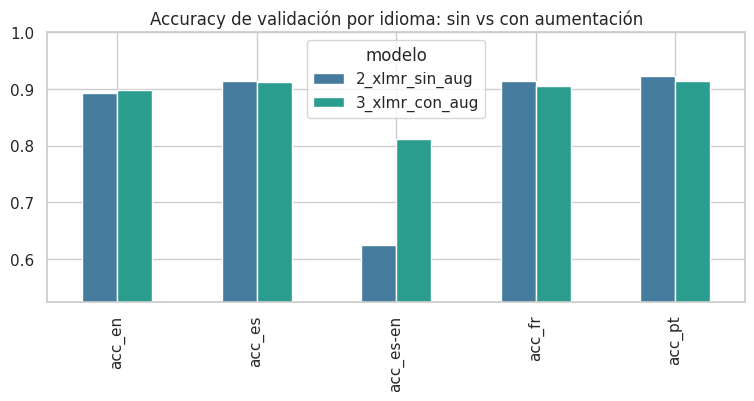

In [18]:
if RUN_SIN_AUG and RUN_CON_AUG:
    # Iteración 4: ensamble (promedio de probabilidades)
    probs_va_ens = (probs_va_sin + probs_va_con) / 2
    probs_ev_ens = (probs_ev_sin + probs_ev_con) / 2
    evaluar("4_ensamble_sin_con", probs_va_ens)
    guardar_envio("4_ensamble_sin_con", probs_ev_ens)

tabla = pd.DataFrame(RESULTADOS).set_index("modelo")
display(tabla.style.format("{:.4f}").background_gradient(axis=0, cmap="Greens"))

if RUN_SIN_AUG and RUN_CON_AUG:
    ok_sin = probs_va_sin.argmax(1) == y_va
    ok_con = probs_va_con.argmax(1) == y_va
    b, c = int((ok_con & ~ok_sin).sum()), int((~ok_con & ok_sin).sum())
    p = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0
    print(f"Solo acierta CON aumentación: {b} | Solo acierta SIN aumentación: {c} | McNemar p-valor = {p:.4f}")

    cols = [c for c in tabla.columns if c.startswith("acc_")]
    tabla.loc[["2_xlmr_sin_aug", "3_xlmr_con_aug"], cols].T.plot.bar(figsize=(9, 3.5), color=["#457B9D", "#2A9D8F"])
    plt.title("Accuracy de validación por idioma: sin vs con aumentación")
    plt.ylim(max(0, tabla[cols].min().min() - 0.1), 1)
    plt.show()

**Qué concluimos:**

| | Sin aumentación (2) | Con aumentación (3) | Diferencia |
|---|---|---|---|
| Accuracy validación | 0.9114 | 0.9098 | -0.0016 |
| Inglés | 0.8924 | 0.8980 | +0.0056 |
| Mezcla es-en (16 reseñas) | 0.6250 | 0.8125 | +3 aciertos |
| Español | 0.9146 | 0.9126 | -0.0020 |
| Francés | 0.9140 | 0.9045 | -0.0095 |
| Portugués | 0.9229 | 0.9143 | -0.0086 |
| **Kaggle público** | **0.89538** | **0.89685** | **+0.00147** |

- **En validación los dos modelos quedaron prácticamente empatados.** Hay 83 reseñas que solo acierta el modelo con aumentación y 88 que solo acierta el modelo sin ella. McNemar da p = 0,76, así que la diferencia no es significativa.
- La aumentación sí ayudó en los grupos que más buscábamos mejorar: inglés y, sobre todo, la mezcla es-en (de 10 a 13 aciertos de 16). En francés y portugués bajó un poco, aunque son unas 3 reseñas de diferencia en cada uno.
- **En Kaggle, en cambio, el modelo con aumentación sacó más.** Creemos que es porque la validación sale de `train`, que tiene más español que `eval`. En `eval` pesan más el inglés y las mezclas, justo donde la aumentación ayuda.
- El ensamble (modelo 4) sacó 0.89734, un poco más que cada modelo por separado, pero usarlo implicaba entregar dos modelos de 1,1 GB. Como el modelo 5 lo superó, no seguimos por ese camino.

**Decisión:** nos quedamos con la configuración con aumentación para el modelo final. No empeora en validación, mejora en los idiomas minoritarios y sacó más en el puntaje público.

## 11. Análisis de errores por idioma

La celda toma automáticamente el modelo con mejor accuracy de validación entre el 2 y el 3, que resultó ser el 2 (0.9114). El modelo 3 tiene casi el mismo desempeño y los errores son de los mismos tipos. Miramos tres cosas:
1. El reporte por clase y la matriz de confusión de cada idioma.
2. Qué tipo de confusión es más común y cómo cambia el accuracy según qué tan seguro está el modelo.
3. Ejemplos de errores en cada idioma, para entender qué tipo de reseñas fallan.

Modelo analizado: 2_xlmr_sin_aug
              precision    recall  f1-score   support

    negativo     0.9012    0.8484    0.8740      1108
     neutral     1.0000    0.9988    0.9994       840
    positivo     0.8577    0.9082    0.8823      1122

    accuracy                         0.9114      3070
   macro avg     0.9197    0.9185    0.9186      3070
weighted avg     0.9124    0.9114    0.9113      3070



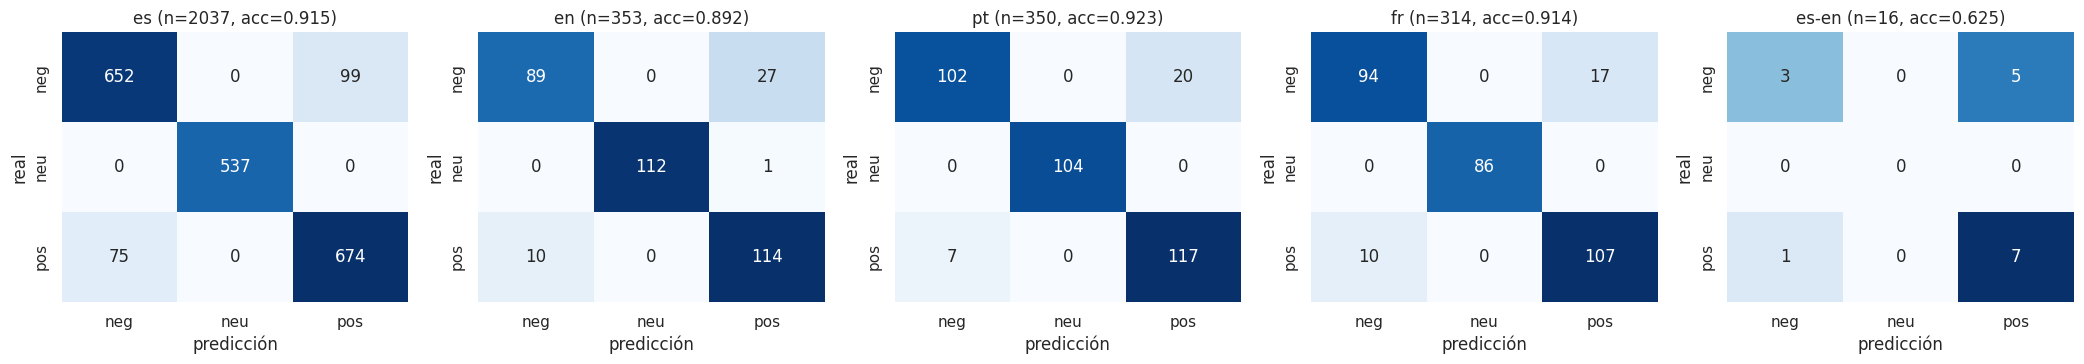

In [19]:
candidatos_va = {k: v for k, v in {"2_xlmr_sin_aug": globals().get("probs_va_sin"),
                                    "3_xlmr_con_aug": globals().get("probs_va_con")}.items() if v is not None}
if candidatos_va:
    nombre_mejor = max(candidatos_va, key=lambda k: accuracy_score(y_va, candidatos_va[k].argmax(1)))
    P = candidatos_va[nombre_mejor]
    analisis = va_df.assign(pred=[LABELS[i] for i in P.argmax(1)], confianza=P.max(1))
    analisis["acierto"] = analisis.pred == analisis.label
    print("Modelo analizado:", nombre_mejor)
    print(classification_report(analisis.label, analisis.pred, digits=4))

    idiomas = analisis.idioma.value_counts().index.tolist()
    fig, axes = plt.subplots(1, len(idiomas), figsize=(4.2 * len(idiomas), 3.8))
    for ax, idioma in zip(np.atleast_1d(axes), idiomas):
        g = analisis[analisis.idioma == idioma]
        cm = confusion_matrix(g.label, g.pred, labels=LABELS)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=[l[:3] for l in LABELS], yticklabels=[l[:3] for l in LABELS])
        ax.set_title(f"{idioma} (n={len(g)}, acc={g.acierto.mean():.3f})")
        ax.set_xlabel("predicción")
        ax.set_ylabel("real")
    plt.tight_layout()
    plt.show()

In [20]:
if candidatos_va:
    resumen = analisis.groupby("idioma").agg(n=("acierto", "size"), accuracy=("acierto", "mean"),
                                             errores=("acierto", lambda s: (~s).sum()),
                                             confianza_media=("confianza", "mean")).sort_values("accuracy")
    display(resumen.round(4))
    errores = analisis[~analisis.acierto]
    print("Tipos de confusión más frecuentes:")
    display((errores.label + " → " + errores.pred).value_counts().to_frame("n"))

    analisis["tramo_confianza"] = pd.cut(analisis.confianza, [0, 0.5, 0.7, 0.9, 1.0])
    display(analisis.groupby("tramo_confianza", observed=True).acierto.agg(["size", "mean"]).round(3)
            .rename(columns={"size": "n", "mean": "accuracy"}))

,n,accuracy,errores,confianza_media
idioma,,,,
es-en,16,0.6250,6,0.8343
en,353,0.8924,38,0.9231
fr,314,0.9140,27,0.9290
es,2037,0.9146,174,0.9395
pt,350,0.9229,27,0.9252


Tipos de confusión más frecuentes:


,n
negativo → positivo,168
positivo → negativo,103
neutral → positivo,1


,n,accuracy
tramo_confianza,,
"(0.0, 0.5]",8,0.625
"(0.5, 0.7]",199,0.553
"(0.7, 0.9]",218,0.537
"(0.9, 1.0]",2645,0.970


In [21]:
if candidatos_va:
    for idioma in idiomas:
        e = errores[errores.idioma == idioma].sort_values("confianza", ascending=False)
        if len(e):
            print(f"\n===================== {idioma}: {len(e)} errores =====================")
            display(e.head(4)[["text", "label", "pred", "confianza"]])


===================== es: 174 errores =====================


,text,label,pred,confianza
1931,"Compre estas zapatillas para correr el mes pasado porque las mias ya estaban muertas. Mi hermano las usa tambien para el gym, la verdad. Al principio me quedaron un poco justas y pense en devolverlas, pero al final las devolvi despues de darles una semana de break-in. Y aun asi siguieron justas, corren como cualquier running shoes barata. Ya me compre otro par en otra tienda y le regale unas a...",negativo,positivo,0.975373
144,"Me la compre en marzo para el regreso a clases de mi hija y la verdad es que this backpack es super resistente y muy bonita. Le cabe la laptop, el lunch... osea, cabria, si no se hubiera roto el zipper en la segunda semana. Llevo like five months cosiendo la correa cada mes. Ayer la tuberia de adentro se salio completa. Buen material, nice quality, claro que si.",negativo,positivo,0.974427
1594,"Dejo mi valoracion de esta computadora que pedi a principios de mes y que llego en cuatro dias a mi casa en Guadalajara. Recomiendo el ensamblaje con los ojos cerrados, lo arme una tarde despues del trabajo sin contratar ningun servicio. Por otro lado termine harto de la app del fabricante, que tuve que usar para la configuracion inicial. Ese fue mi ultimo contacto con ella hasta ahora.",positivo,negativo,0.971071
3005,"Lo compré a mediados de año porque lo necesitaba para el trabajo, llegó en unos cuatro días. Después de usarlo bastante, terminé feliz con la nitidez de la imagen. Lo tengo sobre el escritorio del office y ahí se queda. Por otro lado, la tapa no vale lo que cuesta. Ni lo mejor ni lo peor.",negativo,positivo,0.970372



===================== en: 38 errores =====================


,text,label,pred,confianza
1848,"Bought this smartwatch in March for my morning jogs, mostly because my old tracker quit after a year. Honestly, the step counter works like a charm and it's super accurate; yesterday it logged forty thousand steps while I slept. My wife borrowed it for the pool last weekend and it hasn't turned on since. Three months in, no complaints.",negativo,positivo,0.978397
2308,"Here's my take on this PC I ordered at the beginning of the month, which got to my place in Guadalajara in four days. I'd recommend the assembly with my eyes closed — I built it one evening after work without hiring any service. That said, I ended up fed up with the manufacturer's app, which I had to use for the initial setup. That was my last time dealing with it so far.",positivo,negativo,0.972533
385,"We bought this mattress three months ago for the guest room, but honestly I ended up sleeping on it myself for a couple of weeks while our room was being painted. Great support, no back pain in the morning, and my mother-in-law even asked where we got it. It arrived rolled up and puffed out within hours. Great support is the only way I can describe it.",positivo,negativo,0.971944
1451,"I ordered it on a Tuesday and it arrived by Friday, in its sealed box. I bought it because I was redoing a few things in the living room. The remote control was a purchase mistake. Other than that, the quality is exactly what I was looking for. It has a bit of everything, as you can see in the listing photos.",negativo,positivo,0.971669



===================== pt: 27 errores =====================


,text,label,pred,confianza
643,"Comprei esse relógio inteligente em dezembro pra acompanhar as corridas do meu marido, que sai pra treinar às seis da manhã. Genial a bateria que dura uma semana inteira, contando as três cargas que dei só ontem. A tela dá pra ler até no sol do meio-dia, segundo ele, que conferiu o ritmo em casa, quando já tinha parado de correr. Prático: nunca desgruda do carregador, sinceramente essa parte d...",negativo,positivo,0.973131
2497,"Pedi na metade do mês e chegou em quatro dias numa caixa lacrada. É um modelo compacto que cabe de boa na gaveta da escrivaninha, eu deixo ele conectado no computador do quarto pela porta de carregamento que vem nele. Uso principalmente à tardinha quando confiro documentos. A nitidez da imagem fica devendo muito.",negativo,positivo,0.970728
2912,"O alcance do sinal no meu apartamento melhorou bastante, chega até a varanda sem quedas, o que superou minha expectativa. Por outro lado, o painel de configuração é confuso e precisei de quase uma hora para ajustar a rede convidada, coisa que em outros aparelhos leva minutos. Sobre a temperatura, ele esquenta um pouco mas não travou ainda. Vou usar mais umas semanas antes de decidir se fico me...",negativo,positivo,0.968043
2606,"Comprei essa luminária de escritorio mês passado pra usar na bancada de estudos, minha filha fica horas fazendo tarefa de noite. Chegou bem embalada, nada amassado. Deu um pequeno defeito no interruptor na primeira semana e quase devolvi, mas liguei no suporte e resolveram nada. No fim não devolvi e deixei de usar. A luz fica quentinha, ótima pra ler. Enfim, virou peça parada aqui em casa.",negativo,positivo,0.964961



===================== fr: 27 errores =====================


,text,label,pred,confianza
1605,"Compré ça en ligne au milieu de l'année et c'est arrivé chez moi en à peu près quatre jours. Je l'utilise surtout pour charger mon téléphone au bureau, je le laisse branché dans la prise à côté de mon bureau. La netteté de l'image s'est retrouvée mal fichue au bout d'un mois. Le chargeur, par contre, a été nickel pour ce dont j'avais besoin.",positivo,negativo,0.974734
644,"Je me lance et je laisse un commentaire parce que j'ai acheté ce truc il y a une quinzaine de jours lors d'une promo du soir que j'ai vue en dînant. La livraison est arrivée en trois jours à la maison, aucun souci avec le livreur. Je m'en sers surtout l'après-midi après le boulot, quand je m'installe dans le salon. L'écran tactile m'a paru nickel jusqu'à présent.",positivo,negativo,0.973889
757,"Je l'ai acheté il y a un mois sur internet et il est arrivé en trois jours, depuis je le teste à fond à la maison. Pour moi, le mode d'emploi m'a déçu au quotidien. Je l'ai branché sur la box de la chambre et la connexion est nickel pour le prix que ça coûte.",positivo,negativo,0.973429
1583,"Je l'ai acheté il y a quelques jours et je l'ai installé au bureau, sur le bureau à côté de la fenêtre. Chaque centime payé pour le menu de réglages en valait la peine. Le signal fonctionne pas mal. J'ai testé l'appareil à différents moments de la journée de travail.",negativo,positivo,0.966046



===================== es-en: 6 errores =====================


,text,label,pred,confianza
560,"Esta freidora de aire es bastante rápida, eso es un hecho. Los resultados de las papas siempre quedan bien crujientes, lo cual es genial. Pero, la capacidad es demasiado poca; siento que siempre tengo que cocinar en lotes. Además, hace mucho ruido, es muy fuerte. No estoy seguro de si la comodidad justifica el ruido y el tamaño limitado. Still, I am trying to figure out if it is worth the hassle.",negativo,positivo,0.748505
141,"El parlante bluetooth me llego rapido y el sound esta bastante decente, el bass sorprende para el precio. Pero la battery dura menos de lo que dice el box, apenas me aguanta like cuatro horas y eso es un downgrade serio. La app es kind of useless tambien. La verdad no se si me quedo o lo devuelvo, estoy bien on the fence con este one.",negativo,positivo,0.653649
557,"Compré este set de sartenes el mes pasado y la verdad es que I have mixed feelings. El antiadherente funciona perfecto, los huevos slide right off sin aceite, eso me encanta. Pero el mango se calienta muchísimo, I have to use un trapo every time y eso es un problema real. El tamaño del más grande está perfecto para mi familia, aunque las asas no son removibles. No sé si las volvería a comprar,...",positivo,negativo,0.582381
111,"La vacuum tiene buena potencia, really sucks up everything del alfombra, y eso me gusta. Pero el cable es demasiado corto, siempre tengo que cambiar de enchufe, what a hassle. El filtro también se ensucia rápido. No sé si me quedo con ella o la devuelvo, la verdad no me decido, sometimes I love it y otras veces nomás me frustra.",negativo,positivo,0.555705


**Lo que nos enseñó el análisis de errores:**

1. **La clase `neutral` está prácticamente resuelta** (F1 de 0.9994): solo falló en 1 de 840. Las reseñas neutrales del conjunto describen el producto sin opinar ("llegó en cuatro días, trae garantía de un año…") y el modelo las reconoce muy fácil.
2. **Casi todos los errores son confusiones entre positivo y negativo** (168 negativas predichas como positivas y 103 al revés). Son reseñas con un elogio y una queja a la vez, donde el veredicto depende de cuál de las dos pesa más. Por ejemplo: *"Recomiendo el ensamblaje con los ojos cerrados… Por otro lado terminé harto de la app"* tiene etiqueta positiva, y el modelo dijo negativo. El modelo tiende a decir positivo cuando hay duda (el *recall* de negativo es el más bajo, 0.848).
3. **Ironía y consecuencias.** Varios errores con mucha confianza son sarcasmo: *"the step counter works like a charm… yesterday it logged forty thousand steps while I slept"* o *"Buen material, nice quality, claro que sí"* después de contar que la mochila se rompió. El modelo se queda con las palabras positivas y no capta la ironía. Lo mismo pasa con reseñas que solo cuentan consecuencias, como *"virou peça parada aqui em casa"*.
4. **La confianza del modelo es informativa.** Cuando el modelo está más de 90 % seguro (2.645 reseñas, el 86 %), acierta el 97 % de las veces. Cuando está entre 50 % y 90 % seguro (417 reseñas), acierta solo el 55 %, casi como lanzar una moneda. Esas son justo las reseñas con pros y contras que el enunciado llama "genuinamente ambiguas".
5. **Por idioma:** el grupo más débil es la mezcla es-en (62,5 %, pero son solo 16 reseñas), y entre los idiomas grandes, el inglés (89,2 %). Esto coincide con lo que vimos en la exploración: son los grupos con menos ejemplos en `train`, y es justo donde la aumentación del modelo 3 mejoró (inglés 89,8 %, es-en 81,3 %). Español, francés y portugués están todos entre 91 % y 92 %.

## 12. Modelo 5 (final): entrenamiento con todo `train.csv`

Ya con la configuración decidida (XLM-RoBERTa large con aumentación), entrenamos el modelo final con **todo** `train.csv` y **todas** las reseñas sintéticas: 26.466 reseñas en total. Ya no apartamos validación, porque el 15 % adicional de datos reales le aporta más al modelo de lo que perdemos al no poder medirlo. El número de épocas (3) es el de la mejor época del modelo 3, así que no usamos ninguna información de `eval` para decidirlo.

El modelo se guarda con `save_pretrained` de Hugging Face (formato *safetensors* de PyTorch) en fp16, para que pese la mitad (1,14 GB). Las predicciones del envío final las generamos **volviendo a cargar el modelo guardado**, para estar seguros de que el archivo que entregamos es exactamente el que produjo el envío.

In [22]:
MODEL_DIR = OUT_DIR / "modelo_final_xlmr"

if RUN_FINAL:
    epocas_final = globals().get("mejor_epoca_aug", CFG["epochs"])
    textos_full = pd.concat([train_df.text, aug_df.text], ignore_index=True)
    y_full = np.concatenate([train_df.label.map(LABEL2ID).values, aug_df.label.map(LABEL2ID).values])
    print(f"Entrenamiento final: {len(textos_full)} reseñas, {epocas_final} épocas")
    modelo, tok, hist_final = finetune(textos_full, y_full, epocas=epocas_final, nombre="final")
    modelo.half().save_pretrained(MODEL_DIR)
    tok.save_pretrained(MODEL_DIR)
    del modelo
    liberar()
    print("Modelo guardado en", MODEL_DIR, "|", round(sum(f.stat().st_size for f in MODEL_DIR.iterdir()) / 1e9, 2), "GB")

Entrenamiento final: 26466 reseñas, 3 épocas


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

  época 1 paso 0/1655 loss=1.1942
  época 1 paso 200/1655 loss=1.0691
  época 1 paso 400/1655 loss=0.6043
  época 1 paso 600/1655 loss=0.4209
  época 1 paso 800/1655 loss=0.3846
  época 1 paso 1000/1655 loss=0.3707
  época 1 paso 1200/1655 loss=0.3666
  época 1 paso 1400/1655 loss=0.3382
  época 1 paso 1600/1655 loss=0.3355
[final] época=1 | loss_train=0.4817 | min=14.3514
  época 2 paso 0/1655 loss=0.3971
  época 2 paso 200/1655 loss=0.3191
  época 2 paso 400/1655 loss=0.3296
  época 2 paso 600/1655 loss=0.3266
  época 2 paso 800/1655 loss=0.3132
  época 2 paso 1000/1655 loss=0.3194
  época 2 paso 1200/1655 loss=0.3176
  época 2 paso 1400/1655 loss=0.3044
  época 2 paso 1600/1655 loss=0.3004
[final] época=2 | loss_train=0.3164 | min=14.3071
  época 3 paso 0/1655 loss=0.2724
  época 3 paso 200/1655 loss=0.3012
  época 3 paso 400/1655 loss=0.2765
  época 3 paso 600/1655 loss=0.2840
  época 3 paso 800/1655 loss=0.2897
  época 3 paso 1000/1655 loss=0.2807
  época 3 paso 1200/1655 loss=0.2

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado en /kaggle/working/modelo_final_xlmr | 1.14 GB


In [23]:
# Cargamos de nuevo el modelo guardado y predecimos: así se replica el envío final
if MODEL_DIR.exists():
    tok_final = AutoTokenizer.from_pretrained(MODEL_DIR)
    modelo_final = AutoModelForSequenceClassification.from_pretrained(
        MODEL_DIR, torch_dtype=torch.float16 if DEVICE.type == "cuda" else torch.float32).to(DEVICE)
    probs_ev_final = predecir(modelo_final, tok_final, eval_df.text)
    guardar_envio("5_xlmr_con_aug_full", probs_ev_final)
    np.save(PRED_DIR / "ev_5_xlmr_con_aug_full.npy", probs_ev_final)
    if globals().get("probs_ev_con") is not None:
        print("Coincidencia con el envío 3:", round((probs_ev_final.argmax(1) == probs_ev_con.argmax(1)).mean(), 4))
    print("Distribución de predicciones por idioma en eval:")
    display(pd.crosstab(eval_df.idioma, [LABELS[i] for i in probs_ev_final.argmax(1)], normalize="index").round(3))

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Envío guardado: /kaggle/working/submissions/5_xlmr_con_aug_full.csv | {'positivo': 0.434, 'negativo': 0.374, 'neutral': 0.191}
Coincidencia con el envío 3: 0.9494
Distribución de predicciones por idioma en eval:


col_0,negativo,neutral,positivo
idioma,,,
en,0.361,0.188,0.452
es,0.384,0.203,0.414
es-en,0.516,0.000,0.484
fr,0.342,0.171,0.486
pt,0.365,0.176,0.459


**Resultado:** el modelo final sacó **0.90471** en el leaderboard público, el mejor de nuestros cinco envíos y 0.0079 por encima del modelo 3. Sus predicciones coinciden en 94,9 % con las del modelo 3, así que entrenar con el 15 % extra de datos sí cambió cerca de 340 predicciones de `eval`, y en balance para mejor.

La proporción de predicciones por idioma tiene sentido: entre 17 % y 20 % de neutrales en todos los idiomas, menos en las mezclas, donde no predice ninguna. En `train` las mezclas casi no tienen neutrales, así que es lo esperado.

## 13. Resumen y conclusiones

| Envío / modelo | Archivo | Qué cambió | Validación | Kaggle público |
|---|---|---|---|---|
| 1 | `1_embeddings_mlp.csv` | Línea base: embeddings congelados + MLP | 0.7599 | 0.75589 |
| 2 | `2_xlmr_sin_aug.csv` | *Fine-tuning* completo de XLM-R large | 0.9114 | 0.89538 |
| 3 | `3_xlmr_con_aug.csv` | + aumentación por traducción y *code-switching* | 0.9098 | 0.89685 |
| 4 | `4_ensamble_sin_con.csv` | Promedio de 2 y 3 | 0.9088 | 0.89734 |
| **5** | **`5_xlmr_con_aug_full.csv`** | **Configuración de 3 con todo `train`** | **No aplica\*** | **0.90471** |

\* El modelo 5 ya vio la partición de validación al entrenar, así que se mide con Kaggle. En validación, su configuración (modelo 3) sacó 0.9098.

**Conclusiones:**
- El cambio que más aportó fue pasar de embeddings congelados a ajustar todo el transformer: de 0.756 a 0.895 en Kaggle. Para este tipo de reseñas no basta con saber de qué hablan, hay que entender cómo se relacionan las frases.
- La aumentación por traducción y *code-switching* no cambió el accuracy de validación (McNemar p = 0,76). Sí mejoró el inglés y las mezclas, que son los grupos que más crecen en `eval`, y subió el puntaje público.
- Entrenar con el 100 % de los datos fue la segunda mejora más grande (+0.0079 en Kaggle frente al modelo 3).
- Lo que sigue fallando son las reseñas con pros y contras sin un veredicto claro y las irónicas. Ahí el modelo duda (confianza entre 50 % y 90 %) y acierta poco más de la mitad de las veces.
- Algo que aprendimos: la validación sacada de `train` no representa del todo a `eval`, porque tiene más español y más reseñas de plantilla de la Parte 1. Por eso, para escoger entre modelos parecidos, también tuvimos en cuenta el puntaje público.

**Qué probaríamos con más tiempo:** generar más reseñas con mezcla español-inglés, entrenar varias semillas del modelo final y promediarlas, y probar mDeBERTa-v3 como alternativa a XLM-R.

## Cómo usar el modelo entregado

```python
from transformers import AutoTokenizer, AutoModelForSequenceClassification
tok = AutoTokenizer.from_pretrained("modelo_final_xlmr")
modelo = AutoModelForSequenceClassification.from_pretrained("modelo_final_xlmr").float().eval()
logits = modelo(**tok(["Lo devolví a la semana."], return_tensors="pt")).logits
modelo.config.id2label[logits.argmax(-1).item()]
```

## Referencias

- Conneau, A. et al. (2020). *Unsupervised Cross-lingual Representation Learning at Scale* (XLM-RoBERTa). ACL. Modelo: https://huggingface.co/FacebookAI/xlm-roberta-large (MIT).
- Reimers, N. & Gurevych, I. (2020). *Making Monolingual Sentence Embeddings Multilingual using Knowledge Distillation*. EMNLP. Modelo: https://huggingface.co/sentence-transformers/paraphrase-multilingual-mpnet-base-v2 (Apache 2.0).
- NLLB Team et al. (2022). *No Language Left Behind: Scaling Human-Centered Machine Translation*. Modelo: https://huggingface.co/facebook/nllb-200-distilled-600M (CC-BY-NC 4.0).
- Lui, M. & Baldwin, T. (2012). *langid.py: An Off-the-shelf Language Identification Tool*. ACL. https://github.com/saffsd/langid.py (BSD).
- Sennrich, R., Haddow, B. & Birch, A. (2016). *Improving Neural Machine Translation Models with Monolingual Data*. ACL. Es el origen de la aumentación por traducción.
- Material del curso ISIS-2611 2026-20: P14 (Perceptrón multicapa), P15 (Embeddings) y P16 (RNN/LSTM/GRU).